# Trino queries — Silver layer

Truy vấn star schema Iceberg **Silver** qua Trino và vẽ biểu đồ phân tích.

```bash
pip install trino pandas sqlalchemy sqlalchemy-trino matplotlib
```

Kết nối mặc định: `localhost:8085`, catalog `iceberg`, user `trino`.

In [30]:
%pip install -q trino pandas sqlalchemy sqlalchemy-trino matplotlib

Note: you may need to restart the kernel to use updated packages.


In [31]:
from sqlalchemy import create_engine, text
import pandas as pd
import matplotlib.pyplot as plt

TRINO_HOST = "localhost"
TRINO_PORT = 8085
TRINO_USER = "trino"
TRINO_CATALOG = "iceberg"

engine = create_engine(
    f"trino://{TRINO_USER}@{TRINO_HOST}:{TRINO_PORT}/{TRINO_CATALOG}"
)

def run_sql(sql: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("Connected:", engine.url)

Connected: trino://trino@localhost:8085/iceberg


## 1. Kiểm tra schema / bảng Silver

In [32]:
run_sql("SHOW SCHEMAS FROM iceberg")

,Schema
0,bronze
1,information_schema
2,silver


In [33]:
run_sql("SHOW TABLES FROM iceberg.silver")

,Table
0,dim_category
1,dim_customer
2,dim_date
3,dim_geolocation
4,dim_product
5,dim_seller
6,fact_customer_order
7,fact_order_items
8,fact_orders
9,fact_payments


In [34]:
counts = run_sql("""
SELECT 'dim_customer' AS table_name, COUNT(*) AS row_count FROM iceberg.silver.dim_customer
UNION ALL SELECT 'dim_product', COUNT(*) FROM iceberg.silver.dim_product
UNION ALL SELECT 'dim_seller', COUNT(*) FROM iceberg.silver.dim_seller
UNION ALL SELECT 'dim_category', COUNT(*) FROM iceberg.silver.dim_category
UNION ALL SELECT 'dim_date', COUNT(*) FROM iceberg.silver.dim_date
UNION ALL SELECT 'fact_orders', COUNT(*) FROM iceberg.silver.fact_orders
UNION ALL SELECT 'fact_order_items', COUNT(*) FROM iceberg.silver.fact_order_items
UNION ALL SELECT 'fact_payments', COUNT(*) FROM iceberg.silver.fact_payments
UNION ALL SELECT 'fact_reviews', COUNT(*) FROM iceberg.silver.fact_reviews
UNION ALL SELECT 'fact_customer_order', COUNT(*) FROM iceberg.silver.fact_customer_order
ORDER BY table_name
""")
counts

,table_name,row_count
0,dim_category,74
1,dim_customer,96096
2,dim_date,1096
3,dim_product,32951
4,dim_seller,3095
5,fact_customer_order,94778
6,fact_order_items,111049
7,fact_orders,98059
8,fact_payments,102453
9,fact_reviews,97038


## 2. Doanh thu 2017 theo bang × danh mục

JOIN star schema ad-hoc trên Silver.

In [35]:
revenue_2017 = run_sql("""
SELECT
    c.state,
    COALESCE(cat.product_category_name_english, pr.product_category_name) AS category,
    COUNT(DISTINCT o.order_id) AS total_orders,
    SUM(i.price) AS total_revenue
FROM iceberg.silver.fact_order_items i
JOIN iceberg.silver.fact_orders o ON i.order_key = o.order_key
JOIN iceberg.silver.dim_customer c ON o.customer_key = c.customer_key
JOIN iceberg.silver.dim_product pr ON i.product_key = pr.product_key
LEFT JOIN iceberg.silver.dim_category cat ON pr.category_key = cat.category_key
WHERE o.purchase_date_key BETWEEN 20170101 AND 20171231
GROUP BY c.state, COALESCE(cat.product_category_name_english, pr.product_category_name)
ORDER BY total_revenue DESC
LIMIT 20
""")
revenue_2017

,state,category,total_orders,total_revenue
0,SP,bed_bath_table,1921,207136.78
1,SP,watches_gifts,820,179769.29
2,SP,sports_leisure,1455,170061.49
3,SP,health_beauty,1287,157170.38
4,SP,computers_accessories,967,137822.56
5,SP,furniture_decor,1374,135297.14
6,SP,cool_stuff,760,129243.29
7,SP,toys,941,107550.88
8,SP,housewares,1128,96750.91
9,SP,auto,567,87105.38


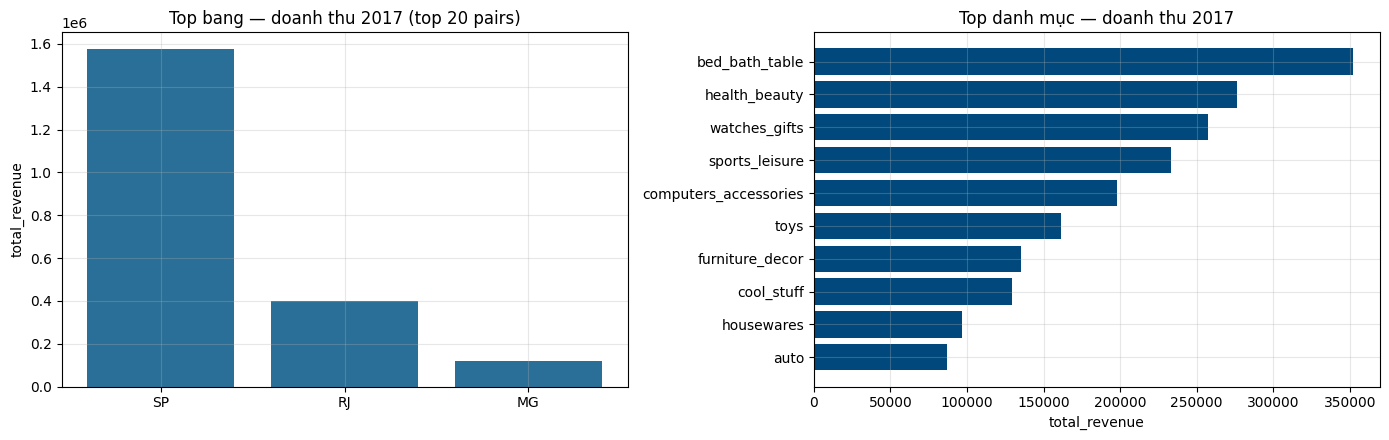

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

by_state = (
    revenue_2017.groupby("state", as_index=False)["total_revenue"]
    .sum()
    .sort_values("total_revenue", ascending=False)
)
axes[0].bar(by_state["state"], by_state["total_revenue"], color="#2a6f97")
axes[0].set_title("Top bang — doanh thu 2017 (top 20 pairs)")
axes[0].set_ylabel("total_revenue")
axes[0].tick_params(axis="x", rotation=0)

by_cat = (
    revenue_2017.groupby("category", as_index=False)["total_revenue"]
    .sum()
    .sort_values("total_revenue", ascending=True)
    .tail(10)
)
axes[1].barh(by_cat["category"], by_cat["total_revenue"], color="#01497c")
axes[1].set_title("Top danh mục — doanh thu 2017")
axes[1].set_xlabel("total_revenue")

plt.tight_layout()
plt.show()

## 3. Xu hướng doanh thu theo tháng

In [37]:
monthly = run_sql("""
SELECT
    d.year,
    d.month,
    CAST(d.year AS VARCHAR) || '-' || LPAD(CAST(d.month AS VARCHAR), 2, '0') AS year_month,
    COUNT(DISTINCT o.order_id) AS orders,
    SUM(i.price) AS revenue
FROM iceberg.silver.fact_order_items i
JOIN iceberg.silver.fact_orders o ON i.order_key = o.order_key
JOIN iceberg.silver.dim_date d ON o.purchase_date_key = d.date_key
GROUP BY d.year, d.month
ORDER BY d.year, d.month
""")
monthly.head(12)

,year,month,year_month,orders,revenue
0,2016,9,2016-09,3,267.36
1,2016,10,2016-10,304,48920.72
2,2016,12,2016-12,1,10.90
3,2017,1,2017-01,788,120124.22
4,2017,2,2017-02,1730,246796.53
5,2017,3,2017-03,2640,374255.30
6,2017,4,2017-04,2367,358096.71
7,2017,5,2017-05,3645,504743.34
8,2017,6,2017-06,3212,432426.20
9,2017,7,2017-07,3937,494904.47


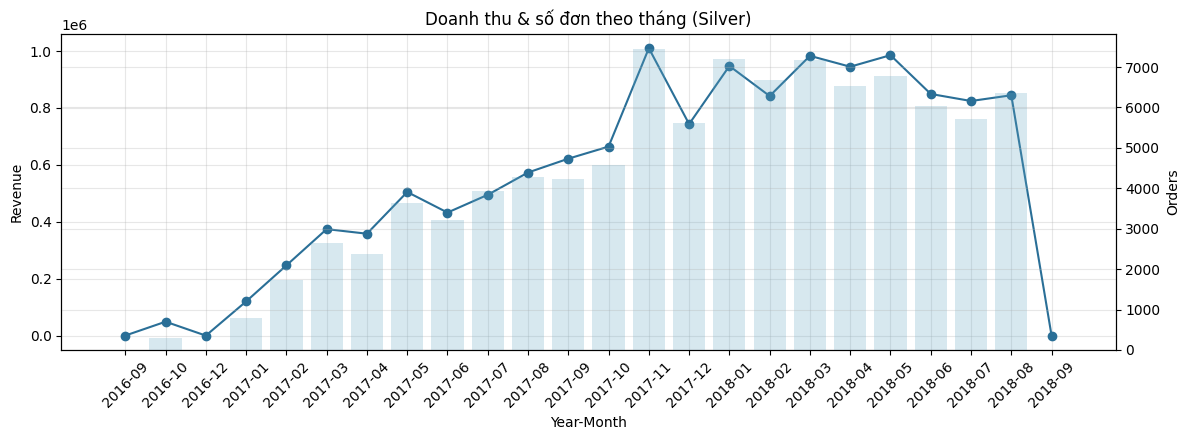

In [38]:
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(monthly["year_month"], monthly["revenue"], marker="o", color="#2a6f97", label="Revenue")
ax1.set_ylabel("Revenue")
ax1.set_xlabel("Year-Month")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.bar(monthly["year_month"], monthly["orders"], alpha=0.25, color="#61a5c2", label="Orders")
ax2.set_ylabel("Orders")

ax1.set_title("Doanh thu & số đơn theo tháng (Silver)")
fig.tight_layout()
plt.show()

## 4. Phân bố trạng thái đơn hàng

In [39]:
order_status = run_sql("""
SELECT order_status, COUNT(*) AS orders
FROM iceberg.silver.fact_orders
GROUP BY 1
ORDER BY orders DESC
""")
order_status

,order_status,orders
0,delivered,95105
1,shipped,1098
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


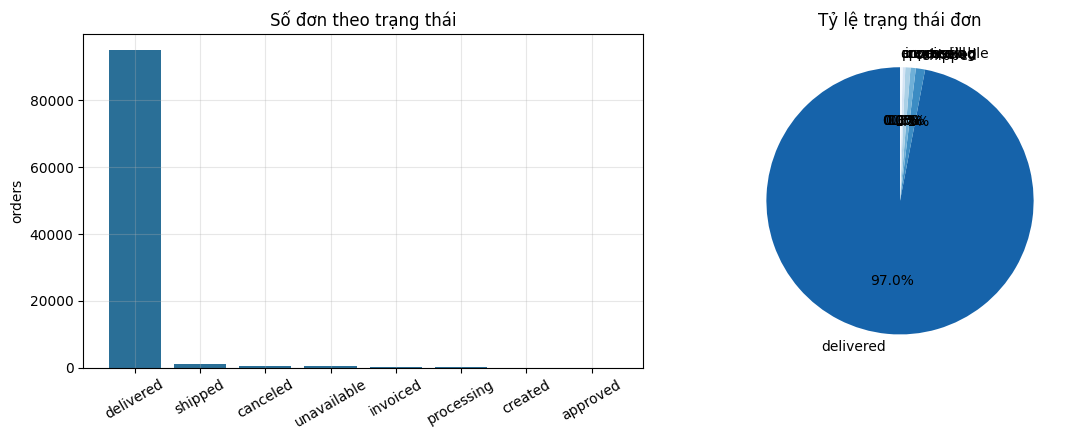

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = plt.cm.Blues_r(range(50, 50 + 40 * len(order_status), 40)[: len(order_status)])

axes[0].bar(order_status["order_status"], order_status["orders"], color="#2a6f97")
axes[0].set_title("Số đơn theo trạng thái")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylabel("orders")

axes[1].pie(
    order_status["orders"],
    labels=order_status["order_status"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
)
axes[1].set_title("Tỷ lệ trạng thái đơn")

plt.tight_layout()
plt.show()

## 5. Phương thức thanh toán

In [41]:
payments = run_sql("""
SELECT
    payment_type,
    COUNT(*) AS payments,
    SUM(payment_value) AS total_value,
    AVG(payment_installments) AS avg_installments
FROM iceberg.silver.fact_payments
GROUP BY payment_type
ORDER BY total_value DESC
""")
payments

,payment_type,payments,total_value,avg_installments
0,credit_card,75764,12379548.36,3.508131
1,boleto,19492,2833112.31,1.000000
2,voucher,5710,374850.67,1.000000
3,debit_card,1484,211873.17,1.000000
4,not_defined,3,0.00,1.000000


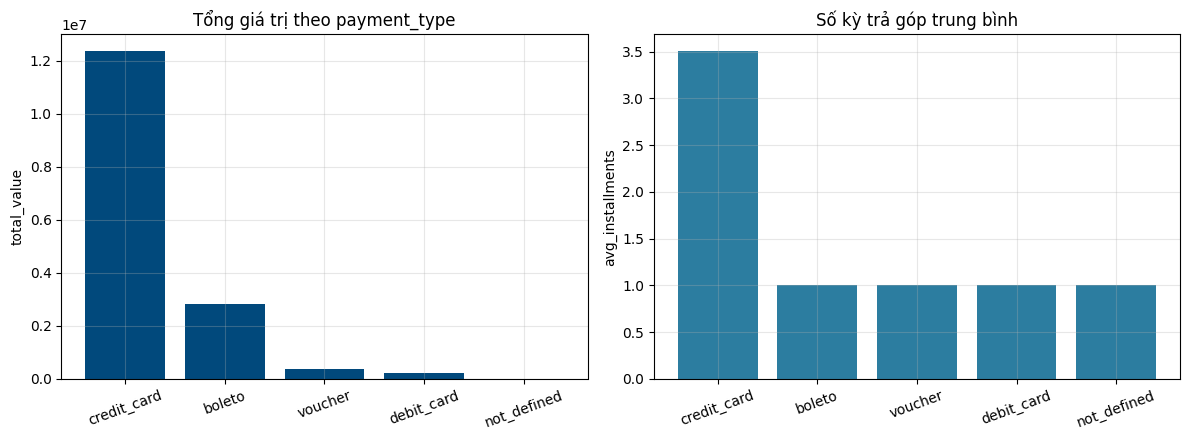

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(payments["payment_type"], payments["total_value"], color="#01497c")
axes[0].set_title("Tổng giá trị theo payment_type")
axes[0].set_ylabel("total_value")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(payments["payment_type"], payments["avg_installments"], color="#2c7da0")
axes[1].set_title("Số kỳ trả góp trung bình")
axes[1].set_ylabel("avg_installments")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 6. Điểm đánh giá (reviews)

In [43]:
reviews = run_sql("""
SELECT
    review_score,
    COUNT(*) AS reviews,
    SUM(CASE WHEN is_positive = 1 THEN 1 ELSE 0 END) AS positive,
    SUM(CASE WHEN is_negative = 1 THEN 1 ELSE 0 END) AS negative
FROM iceberg.silver.fact_reviews
WHERE review_score IS NOT NULL
GROUP BY review_score
ORDER BY review_score
""")
reviews

,review_score,reviews,positive,negative
0,1,11176,0,11176
1,2,3074,0,3074
2,3,8015,0,0
3,4,18736,18736,0
4,5,56037,56037,0


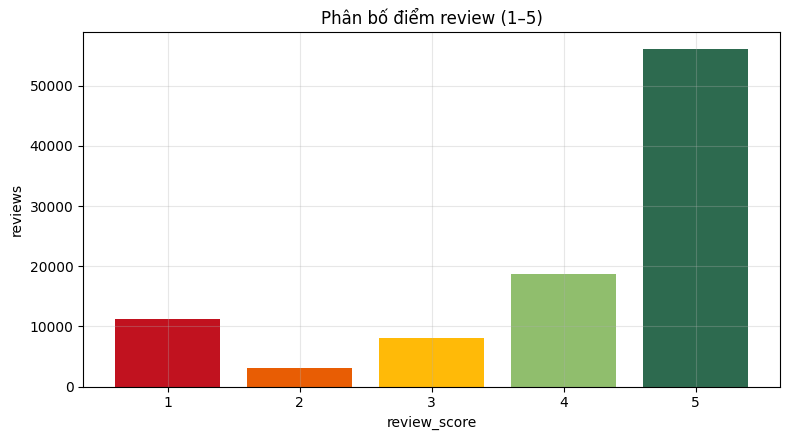

In [44]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bar_colors = ["#c1121f", "#e85d04", "#ffba08", "#90be6d", "#2d6a4f"]
ax.bar(
    reviews["review_score"].astype(str),
    reviews["reviews"],
    color=bar_colors[: len(reviews)],
)
ax.set_title("Phân bố điểm review (1–5)")
ax.set_xlabel("review_score")
ax.set_ylabel("reviews")
plt.tight_layout()
plt.show()

## 7. Top bang theo doanh thu (toàn kỳ)

In [45]:
revenue_by_state = run_sql("""
SELECT
    c.state,
    COUNT(DISTINCT o.order_id) AS orders,
    SUM(i.price) AS revenue,
    AVG(o.delivery_days) AS avg_delivery_days
FROM iceberg.silver.fact_order_items i
JOIN iceberg.silver.fact_orders o ON i.order_key = o.order_key
JOIN iceberg.silver.dim_customer c ON o.customer_key = c.customer_key
WHERE c.state IS NOT NULL
GROUP BY c.state
ORDER BY revenue DESC
LIMIT 15
""")
revenue_by_state

,state,orders,revenue,avg_delivery_days
0,SP,40786,5134626.67,8.305366
1,RJ,12627,1805187.19,14.756581
2,MG,11381,1564509.15,11.587745
3,RS,5347,740620.63,14.791971
4,PR,4917,671320.71,11.557855
5,SC,3556,514468.76,14.607293
6,BA,3312,505978.66,18.818932
7,DF,2086,295695.76,12.573962
8,GO,1968,288667.84,15.028175
9,ES,1999,271504.02,15.252957


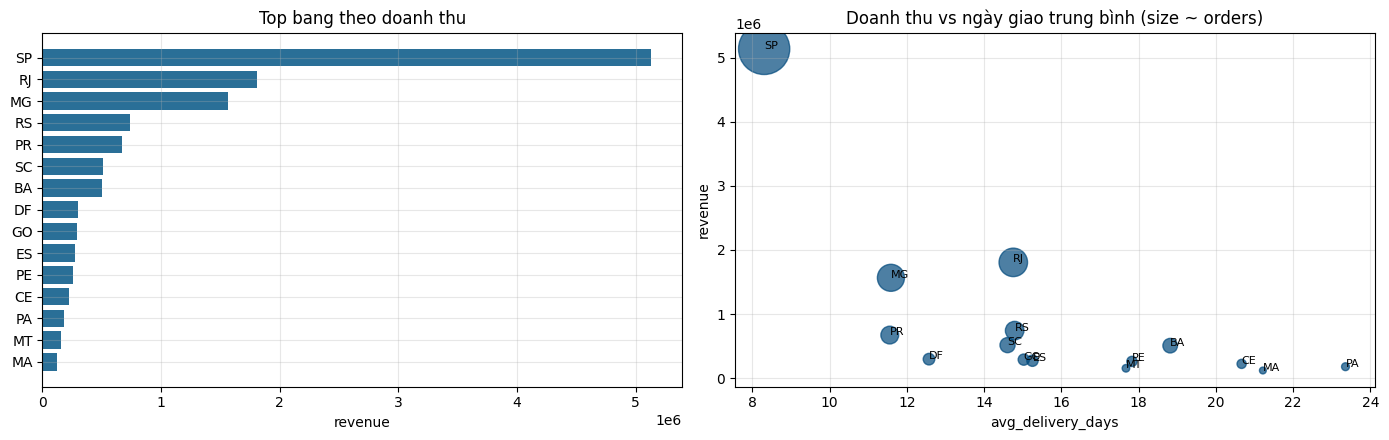

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].barh(
    revenue_by_state.sort_values("revenue")["state"],
    revenue_by_state.sort_values("revenue")["revenue"],
    color="#2a6f97",
)
axes[0].set_title("Top bang theo doanh thu")
axes[0].set_xlabel("revenue")

axes[1].scatter(
    revenue_by_state["avg_delivery_days"],
    revenue_by_state["revenue"],
    s=revenue_by_state["orders"] / 30,
    alpha=0.7,
    c="#01497c",
)
for _, row in revenue_by_state.iterrows():
    axes[1].annotate(row["state"], (row["avg_delivery_days"], row["revenue"]), fontsize=8)
axes[1].set_title("Doanh thu vs ngày giao trung bình (size ~ orders)")
axes[1].set_xlabel("avg_delivery_days")
axes[1].set_ylabel("revenue")

plt.tight_layout()
plt.show()

## 8. Top danh mục sản phẩm

In [47]:
top_categories = run_sql("""
SELECT
    COALESCE(cat.product_category_name_english, pr.product_category_name) AS category,
    COUNT(DISTINCT o.order_id) AS orders,
    SUM(i.price) AS revenue,
    AVG(r.review_score) AS avg_review_score
FROM iceberg.silver.fact_order_items i
JOIN iceberg.silver.fact_orders o ON i.order_key = o.order_key
JOIN iceberg.silver.dim_product pr ON i.product_key = pr.product_key
LEFT JOIN iceberg.silver.dim_category cat ON pr.category_key = cat.category_key
LEFT JOIN iceberg.silver.fact_reviews r ON o.order_key = r.order_key
GROUP BY COALESCE(cat.product_category_name_english, pr.product_category_name)
ORDER BY revenue DESC
LIMIT 12
""")
top_categories

,category,orders,revenue,avg_review_score
0,health_beauty,8684,1238165.03,4.137326
1,watches_gifts,5525,1189876.33,4.018331
2,bed_bath_table,9275,1030078.94,3.896811
3,sports_leisure,7636,980035.30,4.105381
4,computers_accessories,6600,903514.07,3.933943
5,furniture_decor,6373,722985.08,3.911982
6,cool_stuff,3593,631219.59,4.147422
7,housewares,5774,621963.30,4.058449
8,auto,3836,587353.48,4.057282
9,garden_tools,3472,480962.75,4.039110


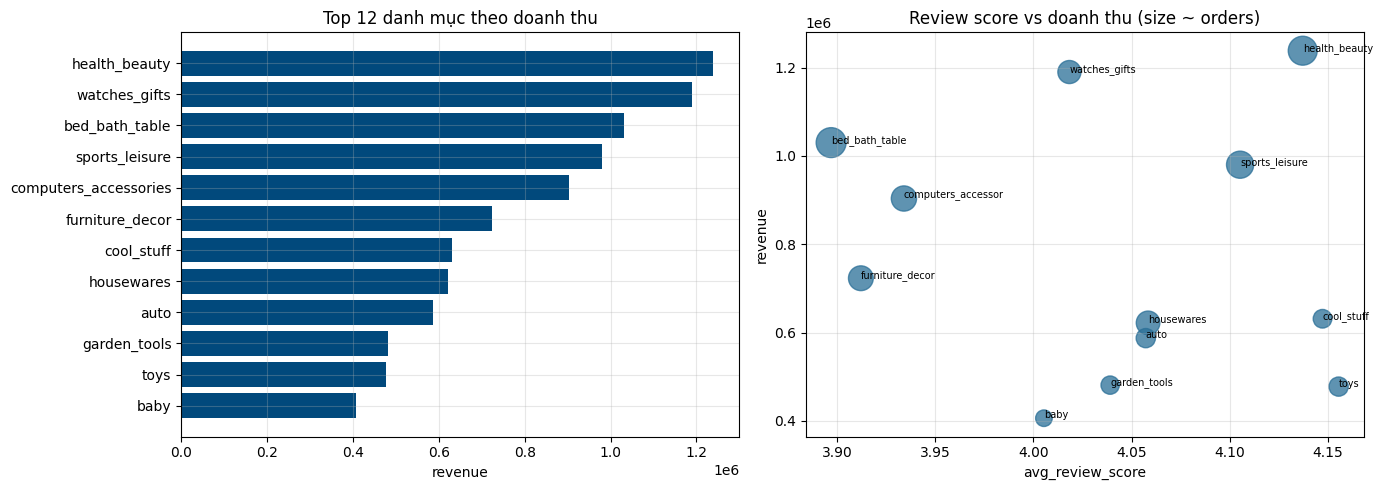

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_df = top_categories.sort_values("revenue")
axes[0].barh(plot_df["category"], plot_df["revenue"], color="#01497c")
axes[0].set_title("Top 12 danh mục theo doanh thu")
axes[0].set_xlabel("revenue")

axes[1].scatter(
    top_categories["avg_review_score"],
    top_categories["revenue"],
    s=top_categories["orders"] / 20,
    alpha=0.75,
    c="#2a6f97",
)
for _, row in top_categories.iterrows():
    axes[1].annotate(
        str(row["category"])[:18],
        (row["avg_review_score"], row["revenue"]),
        fontsize=7,
    )
axes[1].set_title("Review score vs doanh thu (size ~ orders)")
axes[1].set_xlabel("avg_review_score")
axes[1].set_ylabel("revenue")

plt.tight_layout()
plt.show()

## 9. Top khách theo số đơn / chi tiêu

In [49]:
top_customers = run_sql("""
SELECT
    c.customer_unique_id,
    c.state,
    co.order_count,
    co.total_spent,
    co.average_order_value,
    co.average_delivery_days
FROM iceberg.silver.fact_customer_order co
JOIN iceberg.silver.dim_customer c ON co.customer_key = c.customer_key
ORDER BY co.total_spent DESC
LIMIT 15
""")
top_customers

,customer_unique_id,state,order_count,total_spent,average_order_value,average_delivery_days
0,0a0a92112bd4c708ca5fde585afaa872,RJ,1,13664.08,13664.0800,18.0
1,46450c74a0d8c5ca9395da1daac6c120,SC,3,9553.02,3184.3400,8.0
2,da122df9eeddfedc1dc1f5349a1a690c,RJ,2,7571.63,3785.8150,15.0
3,763c8b1c9c68a0229c42c9fc6f662b93,ES,1,7274.88,7274.8800,11.0
4,dc4802a71eae9be1dd28f5d788ceb526,MS,1,6929.31,6929.3100,18.0
5,459bef486812aa25204be022145caa62,ES,1,6922.21,6922.2100,20.0
6,ff4159b92c40ebe40454e3e6a7c35ed6,SP,1,6726.66,6726.6600,11.0
7,4007669dec559734d6f53e029e360987,MG,1,6081.54,6081.5400,19.0
8,5d0a2980b292d049061542014e8960bf,GO,1,4809.44,4809.4400,NaN
9,eebb5dda148d3893cdaf5b5ca3040ccb,SP,1,4764.34,4764.3400,18.0


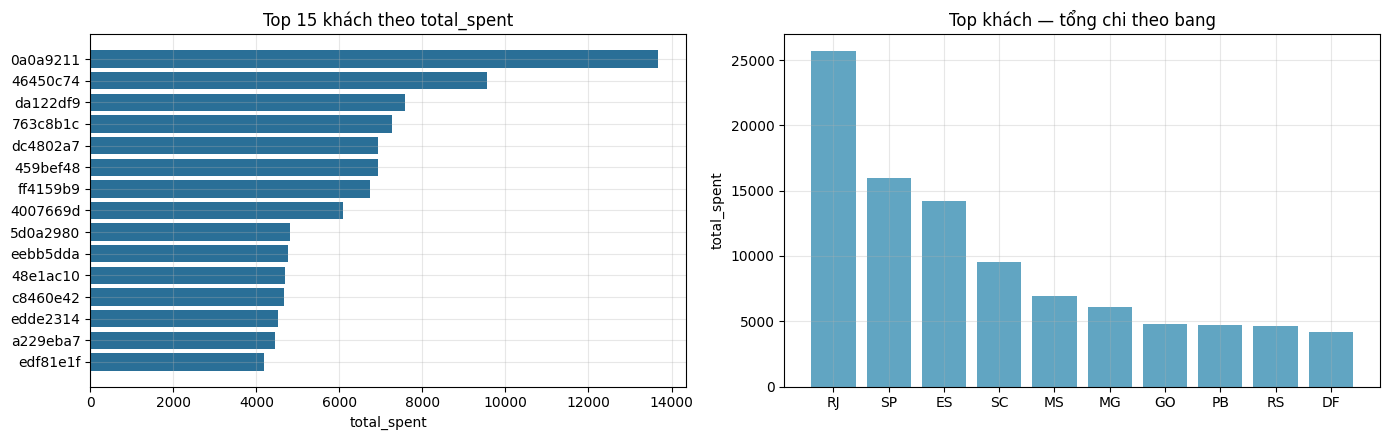

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

labels = top_customers["customer_unique_id"].str[:8]
axes[0].barh(labels[::-1], top_customers["total_spent"][::-1], color="#2a6f97")
axes[0].set_title("Top 15 khách theo total_spent")
axes[0].set_xlabel("total_spent")

state_spend = (
    top_customers.groupby("state", as_index=False)["total_spent"]
    .sum()
    .sort_values("total_spent", ascending=False)
)
axes[1].bar(state_spend["state"], state_spend["total_spent"], color="#61a5c2")
axes[1].set_title("Top khách — tổng chi theo bang")
axes[1].set_ylabel("total_spent")

plt.tight_layout()
plt.show()

## 10. Giao hàng: delay & thời gian giao

In [51]:
delivery = run_sql("""
SELECT
    CASE
        WHEN delivery_delay_days IS NULL THEN 'unknown'
        WHEN delivery_delay_days <= 0 THEN 'on_time_or_early'
        WHEN delivery_delay_days BETWEEN 1 AND 3 THEN 'delay_1_3d'
        WHEN delivery_delay_days BETWEEN 4 AND 7 THEN 'delay_4_7d'
        ELSE 'delay_8d_plus'
    END AS delay_bucket,
    COUNT(*) AS orders,
    AVG(delivery_days) AS avg_delivery_days
FROM iceberg.silver.fact_orders
WHERE is_delivered = 1
GROUP BY 1
ORDER BY orders DESC
""")
delivery

,delay_bucket,orders,avg_delivery_days
0,on_time_or_early,88587,10.585323
1,delay_8d_plus,2855,44.019965
2,delay_1_3d,1860,22.847849
3,delay_4_7d,1795,27.772702
4,unknown,8,NaN


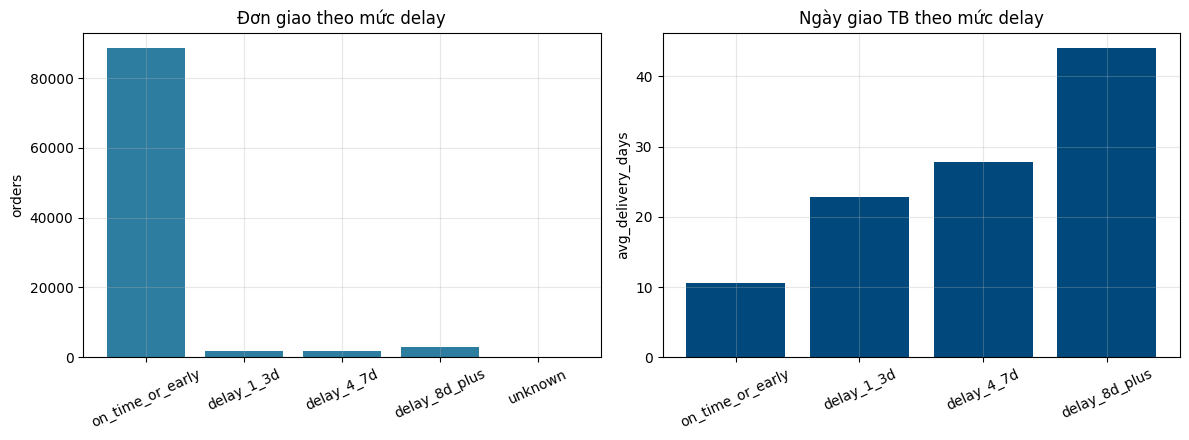

In [52]:
order_map = {
    "on_time_or_early": 0,
    "delay_1_3d": 1,
    "delay_4_7d": 2,
    "delay_8d_plus": 3,
    "unknown": 4,
}
delivery_plot = delivery.copy()
delivery_plot["sort_key"] = delivery_plot["delay_bucket"].map(order_map)
delivery_plot = delivery_plot.sort_values("sort_key")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(delivery_plot["delay_bucket"], delivery_plot["orders"], color="#2c7da0")
axes[0].set_title("Đơn giao theo mức delay")
axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylabel("orders")

axes[1].bar(delivery_plot["delay_bucket"], delivery_plot["avg_delivery_days"], color="#01497c")
axes[1].set_title("Ngày giao TB theo mức delay")
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_ylabel("avg_delivery_days")

plt.tight_layout()
plt.show()